# Рекомендации поэзии на Goodreads

**Датасет:** Goodreads Book Graph, жанровая подвыборка *Poetry* (UCSD; Wan & McAuley, RecSys 2018) - <https://cseweb.ucsd.edu/~jmcauley/datasets/goodreads.html>

**Задача:** для каждого пользователя предложить 10 поэтических книг, которые он **добавит на полку и оценит на 4-5 звёзд** в следующем периоде.
Сравниваем пять реализованных с нуля моделей на одной и той же отложенной тестовой выборке

| # | модель | файл |
|---|---|---|
| 1 | Item-based CF (косинус со сжатием) | `models/item_knn.py` |
| 2 | iALS (Hu, Koren, Volinsky) | `models/ials.py` |
| 3 | EASE | `models/ease.py` |
| 4 | Factorization Machine + BPR с метапризнаками | `models/fm.py` |
| 5 | iALS с собственным целевым сигналом | `models/ials_custom.py`, `core/signals.py` |

**Запуск** (Python ≥ 3.11):

```bash
uv sync                               # или: pip install -r requirements.txt
uv run python scripts/download_data.py   # ~240 МБ в data/raw, проверка sha256
uv run python scripts/prepare_data.py    # raw → interim → processed (~5 с)
uv run jupyter nbconvert --execute --to notebook --inplace experiments.ipynb
```

Подбор и тест кешируются в `artifacts/`; На моем компьютере с 5060 TI 16 GB Vram ноутбук выполняется за 30 минут

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import polars as pl
import torch

import config
from core import data, eda, experiment as ex, plots, report, split
from core.evaluate import evaluate, summary_row
from core.seed import seed_everything
from models.popularity import Popularity, Random

FORCE = False                         # True - пересчитать подбор и тест, игнорируя кеш
seed_everything(config.SEED)
plots.use()
pl.Config.set_tbl_rows(30); pl.Config.set_tbl_width_chars(160); pl.Config.set_fmt_str_lengths(80)
print(f"SEED={config.SEED}  K={config.K}  основная метрика: {config.PRIMARY_METRIC}")
print("torch", torch.__version__, "| устройство:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

SEED=42  K=10  основная метрика: ndcg@10
torch 2.14.1+cu130 | устройство: NVIDIA GeForce RTX 5060 Ti


## 1. Данные

**Источник.** UCSD Book Graph, опубликован авторами статей
*Item Recommendation on Monotonic Behavior Chains* (RecSys 2018) и *Fine-grained Spoiler Detection* (ACL 2019).
Берём жанровую подвыборку **Poetry**: она целиком укладывается в лимит задания и не требует сэмплирования пользователей.
Файлы скачиваются напрямую с `mcauleylab.ucsd.edu` скриптом `scripts/download_data.py`:

| файл | что внутри | поля, которые используем |
|---|---|---|
| `goodreads_interactions_poetry.json.gz` | одна запись - пара пользователь-книга (издание) на полке | `user_id`, `book_id`, `is_read`, `rating` (0 - без оценки, 1-5), `date_added`, `date_updated`, `read_at` |
| `goodreads_books_poetry.json.gz` | метаданные изданий | `work_id`, `title`, `authors`, `publication_year`, `num_pages`, `format`, `language_code`, `publisher`, `description` |
| `goodreads_reviews_poetry.json.gz` | тексты рецензий | факт и дата рецензии (`user_id`, `book_id`, `date_added`) |
| `goodreads_book_authors.json.gz` | авторы | имя автора - только для показа |

**Взаимодействие** - добавление книги на полку. У записи три уровня: только полка (обычно *to-read*), прочитано, оценка 1-5.
**Объект рекомендации** - произведение (`work_id`): разные издания одной книги склеиваем.
**Релевантно** - произведение, которое пользователь впервые добавил в окне val/test и оценил на ≥ 4 до конца окна.
Это единый критерий для всех моделей: обучающие таргеты моделей его не меняют.

In [2]:
inter, books = data.load_interim("interactions"), data.load_interim("books")
events, items, summary = data.load_processed()
print(f"исходно: {inter.height:,} записей, {inter['user_id'].n_unique():,} пользователей, {books.height:,} изданий")
print(f"после очистки: {summary['n_interactions']:,} пар, {summary['n_users']:,} пользователей, {summary['n_items']:,} произведений")
inter.head(3)

исходно: 2,734,350 записей, 377,799 пользователей, 36,514 изданий
после очистки: 1,315,602 пар, 32,599 пользователей, 10,096 произведений


user_id,book_id,is_read,rating,t_added,t_updated,t_read_at
str,str,bool,i8,"datetime[μs, UTC]","datetime[μs, UTC]","datetime[μs, UTC]"
"""8842281e1d1347389f2ab93d60773d4d""","""1384""",true,4,2007-05-09 16:33:44 UTC,2007-05-09 16:33:44 UTC,null
"""8842281e1d1347389f2ab93d60773d4d""","""1376""",true,4,2007-05-09 16:33:18 UTC,2007-05-09 16:33:18 UTC,null
"""8842281e1d1347389f2ab93d60773d4d""","""30119""",true,5,2007-01-13 21:44:20 UTC,2017-03-22 18:45:08 UTC,1983-03-01 08:00:00 UTC


**Пайплайн эксперимента:** сырые JSON (4 файла, 2.7 млн записей) → очистка событий, издания → произведения →
15-core только по train-периоду → глобальное разбиение train | val | test → 5 моделей + бейзлайны → NDCG@10, Recall@10.
Все модели получают одну историю, одних пользователей и один каталог кандидатов.

## 2. EDA и подготовка

### Пропуски и дубликаты

In [3]:
eda.quality_table(inter, books)

таблица,проверка,строк,%
str,str,i64,f64
"""взаимодействия""","""записей""",2734350,100.0
"""взаимодействия""","""дубли пар (user, book)""",0,0.0
"""взаимодействия""","""без оценки (rating = 0)""",1505291,55.05
"""взаимодействия""","""без read_at""",2309891,84.48
"""взаимодействия""","""date_added не распознана""",0,0.0
"""взаимодействия""","""date_added < 2007""",146,0.01
"""книги""","""записей""",36514,100.0
"""книги""","""без work_id""",0,0.0
"""книги""","""без description""",7526,20.61


- Дубликаты `(user_id, book_id)`: 0; при подготовке применяется удаление дублей.
- `rating = 0`: 55,05% записей; оценка отсутствует, взаимодействие сохраняется как неявный сигнал.
- `read_at`: отсутствует у 84,48% записей; для прочитанных книг используется `date_updated`, если `read_at` не указан. Время прочтения ограничивается снизу датой добавления.
- `date_added`: нераспознанных дат нет; 146 записей раньше 2007 года исключаются. Сохраняются даты в интервале `[2007-01-01, 2017-11-01)`.
- Метаданные: язык отсутствует у 53,3% изданий, описание у 20,61%, страницы у 20,55%, издатель у 16,52%, год у 15,93%, формат у 19,24%. Пропусков `work_id` и авторов нет.
- Пропуски FM: год, страницы и средняя оценка пользователя получают отдельную корзину; пропуски языка, формата и издателя объединяются с редкими значениями в `<другое>`; пустое описание даёт нулевой TF-IDF-вектор.


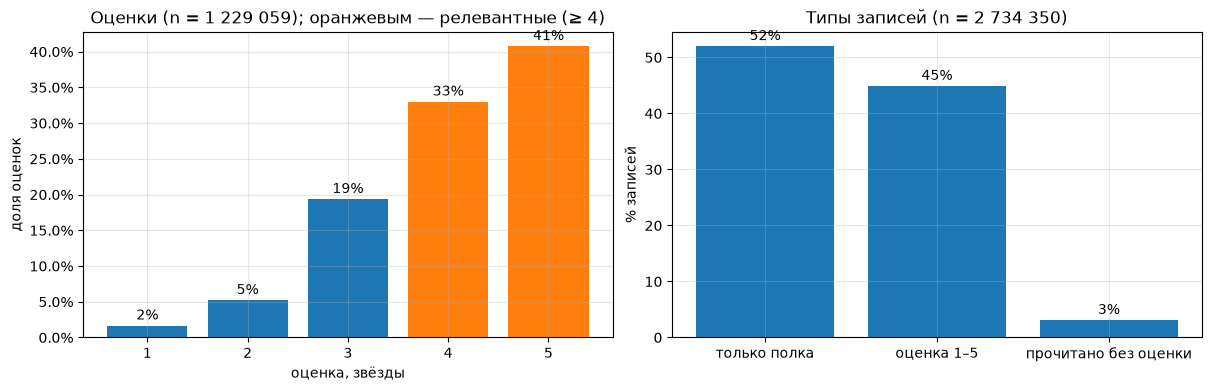

In [4]:
eda.fig_ratings_and_kinds(inter);

Оценки смещены вверх: 74% - 4 и 5 звёзд. Поэтому оценка 4 у «щедрого» читателя значит меньше, чем у строгого, - на этом построен
сигнал модели 5. Больше половины записей - полка без оценки: слабое намерение, которое модели 2 и 5 используют по-разному.

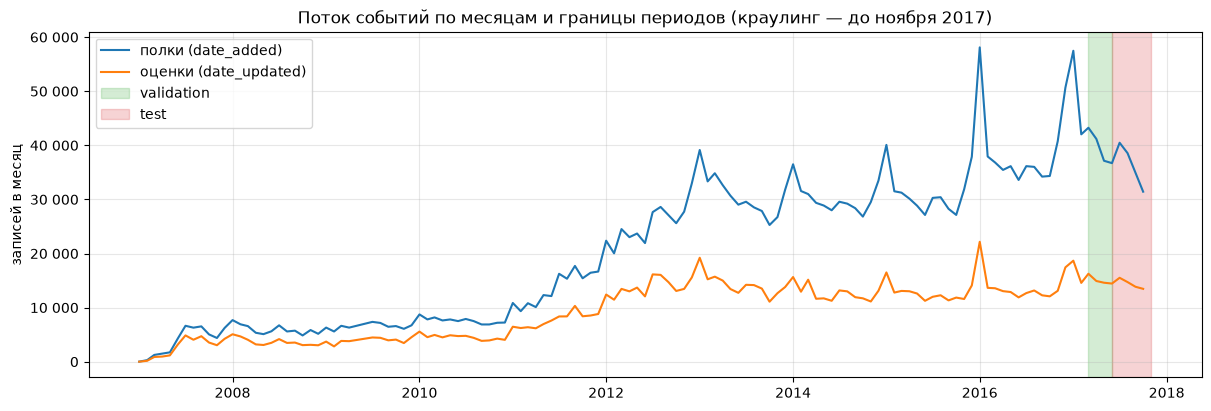

In [5]:
eda.fig_timeline_volume(inter);

Поток растёт до 2013 года и дальше стабилен; пики в январе - новогодние «челленджи» чтения.
Границы периодов: **train** - до 2017-03-01, **val** - март-май 2017, **test** - июнь-октябрь 2017
(ноябрь 2017 неполный - сбор данных с сайта закончился).

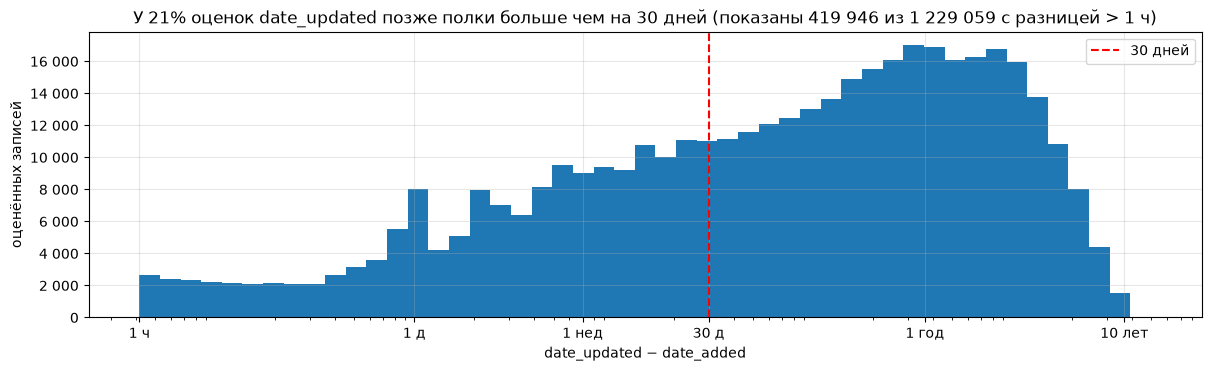

In [6]:
eda.fig_lag(inter);

**Почему нужна модель событий.** Запись - финальное состояние пары на момент сбора данных с сайта. Пользователь мог добавить книгу в *to-read*
в 2015 году, а оценить в 2017. Если взять запись целиком по `date_added`, оценка 2017 года утечёт в train.
Поэтому разносим запись на события: полка (`date_added`), прочтение (`read_at`, иначе `date_updated`), оценка (`date_updated` -
самое позднее известное время, консервативно), рецензия (дата рецензии). На cutoff модель видит пару, только если полка раньше cutoff,
а оценку - только если и она раньше cutoff (`core/split.py`, тест `tests/test_split.py`).

### Активность, популярность и разреженность (после очистки)

{'пары': 1315602,
 'пользователи': 32599,
 'произведения': 10096,
 'плотность, %': 0.4,
 'медиана пар на пользователя': 26.0,
 'медиана пар на произведение': 43.0}

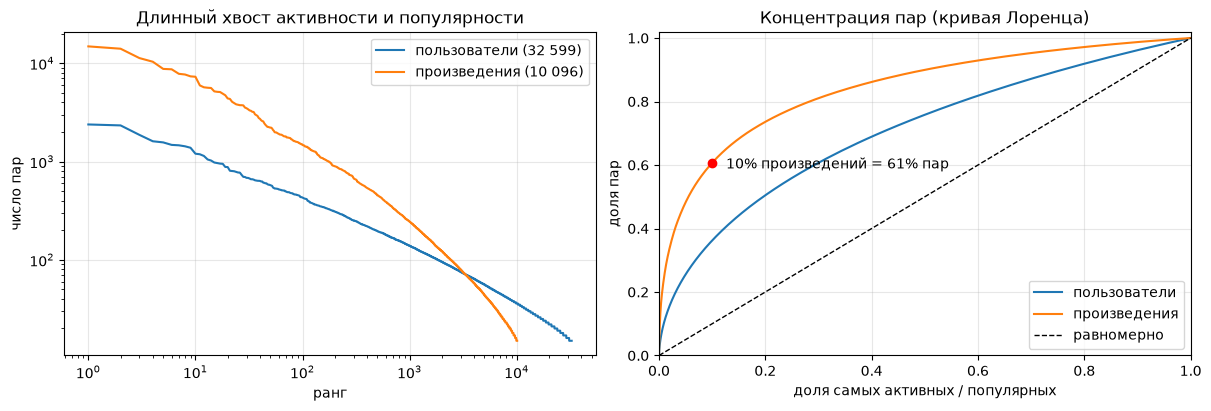

In [7]:
eda.fig_long_tail(events);
eda.sparsity(events)

Медианный пользователь - 26 пар, медианное произведение - 43 пары; плотность 0.4%. 10% самых популярных произведений собирают
около 60% пар, поэтому популярность - сильный baseline, а покрытие каталога - важная вторичная характеристика.

### Метаданные

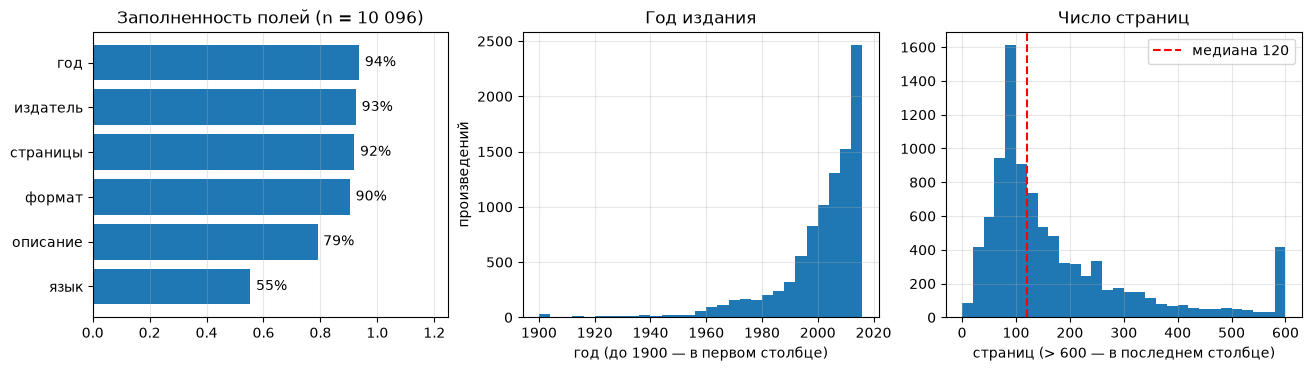

In [8]:
eda.fig_metadata(items);

Для FM берём только **статичные** поля книги: авторы, год, страницы, формат, язык, издатель, описание (TF-IDF).
Поля `average_rating`, `ratings_count`, `text_reviews_count`, `popular_shelves`, `similar_books` посчитаны на момент сбора данных с сайта
с учётом будущих оценок - в момент рекомендации их бы не было, поэтому не используем.
Признаки пользователя строим только из его истории до cutoff.

### Очистка и подвыборка

1. Удаляем записи с датой полки вне [2007-01-01, 2017-11-01).
2. Склеиваем издания в произведения по `work_id` (36.5 тыс. изданий → 25.6 тыс. произведений): пользователь, читавший одно издание,
   не должен получать рекомендацию другого издания той же книги. Для пары берём первую полку и последнюю оценку.
3. **15-core только по train-периоду** (полки до 2017-03-01): у каждого пользователя и произведения ≥ 15 пар.
   k-core по всему периоду использовал бы будущие события для отбора. Пары val/test оставшихся пользователей и произведений сохраняем.

Отбор детерминирован (без случайного сэмплирования) и воспроизводится `scripts/prepare_data.py`.

пар после 2017-03-01 до k-core: 302,020; из них холодные пользователи: 207,251, холодные произведения у тёплых пользователей: 19,016


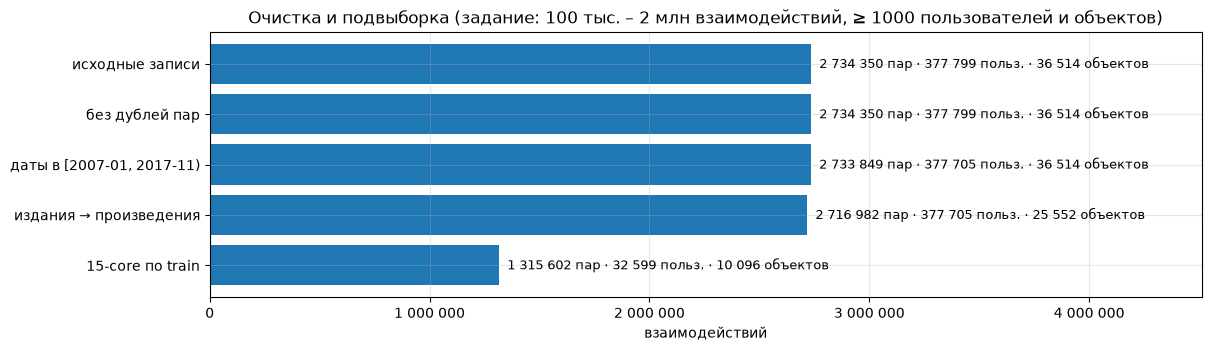

In [9]:
eda.fig_funnel(summary);
cold = summary["cold"]
print(f"пар после 2017-03-01 до k-core: {cold['future_pairs']:,}; из них холодные пользователи: {cold['future_pairs_cold_user']:,}, "
      f"холодные произведения у тёплых пользователей: {cold['future_pairs_cold_item']:,}")

## 3. Протокол оценки

- **Разбиение - глобальное по календарю** (как в семинарах 05/06): история до cutoff, цели - следующее окно.
  Подбор: история до 2017-03-01, цели март-май. Тест: refit на train + val (история до 2017-06-01), цели июнь-октябрь; один прогон после выбора настроек.
- **Кандидаты** - все произведения каталога, у которых есть хотя бы одна полка до cutoff.
- **Исключаем** всё, что пользователь добавил до cutoff, включая to-read и низкие оценки: задача - открытие новых книг.
- **Новые пользователи и объекты.** Модели работают в warm-start постановке: пользователи и произведения отобраны 15-core по train.
  Пары вне подвыборки посчитаны выше; пользователей без релевантных книг в окне не оцениваем.
- **Одинаково для всех моделей:** одна история, один каталог, один seen-filter, одни пользователи (`core/evaluate.py`).

In [10]:
stages = split.make_stages(events, items)
val, test = stages["val"], stages["test"]
pl.DataFrame([{"этап": s.name, **s.stats} for s in stages.values()])

этап,history_pairs,history_users,catalog_items,window_pairs,relevant_pairs,relevant_out_of_catalog,relevant_cold_user,eval_users,eval_targets
str,i64,i64,i64,i64,i64,i64,i64,i64,i64
"""val""",1239849,32599,10096,34857,4735,0,0,2555,4735
"""test""",1274706,32599,10096,40896,6042,0,0,3119,6042


### Метрики (K = 10)

Для пользователя $u$ с релевантными книгами $H_u$ и списком $L_u$ длины $K$:

$$\mathrm{NDCG@K}_u=\frac{\sum_{r=1}^{K}\mathbf 1[L_{u,r}\in H_u]/\log_2(r+1)}{\sum_{r=1}^{\min(K,|H_u|)}1/\log_2(r+1)},\qquad
\mathrm{Recall@K}_u=\frac{|L_u\cap H_u|}{|H_u|}.$$

**Основная метрика - NDCG@10**,**Recall@10 - дополнительная**. И другие

### Бейзлайны

**Random** - нижняя граница; **Popularity** - число полок за всё время до cutoff;
**Recent popularity** - полки только за последние $w$ дней до cutoff («что читают сейчас»), $w$ подбирается на validation.
Последний важен для честности: если модель выигрывает только за счёт свежих трендов, свежая популярность это покажет.

In [11]:
pop_grid, best_pop = ex.tune_popularity(val, FORCE)
rnd_val = evaluate(Random().fit(val.history), val)
print("лучшее окно:", best_pop)
pl.concat([pl.DataFrame([summary_row("Random", rnd_val)]),
           pop_grid.select(pl.format("Popularity, окно {} дн.", pl.col("window_days").cast(pl.Utf8).fill_null("∞")).alias("model"),
                           pl.exclude("window_days", "fit_s"))], how="diagonal_relaxed").with_columns(pl.selectors.float().round(4))

лучшее окно: {'window_days': 30}


model,ndcg@10,recall@10,precision@10,hit@10,coverage@10,pop_rank_mean,users
str,f64,f64,f64,f64,f64,f64,i64
"""Random""",0.0007,0.0012,0.0003,0.0031,0.8691,0.506,2555
"""Popularity, окно ∞ дн.""",0.0254,0.0421,0.0067,0.0614,0.0051,0.0007,2555
"""Popularity, окно 30 дн.""",0.0759,0.1038,0.0137,0.1335,0.0028,0.0128,2555
"""Popularity, окно 90 дн.""",0.0628,0.1004,0.013,0.1276,0.0033,0.0115,2555
"""Popularity, окно 180 дн.""",0.0637,0.1028,0.0134,0.1307,0.0035,0.011,2555
"""Popularity, окно 365 дн.""",0.0749,0.1002,0.0132,0.128,0.0032,0.0044,2555


## 4. Модели и подбор на validation

Для каждой модели - сетка из `config.py`, выбор по val NDCG@10. Test в подборе не участвует.

### 4.1 Item-based CF

$X$ - бинарная матрица взаимодействий. Сходство произведений - косинус со сжатием по числу общих пользователей $n_{ij}$:

$$s(i,j)=\frac{n_{ij}}{\sqrt{n_i n_j}}\frac{n_{ij}}{n_{ij}+\lambda},\quad s(i,i)=0,\qquad
\mathrm{score}(u,j)=\sum_{i\in I_u\cap N_k(j)}s(i,j).$$

$n_i$ - число пользователей произведения $i$; $N_k(j)$ - $k$ соседей кандидата $j$. Сжатие уменьшает сходство при малом числе общих пользователей.

Сетка: $k\in\{50,100,200,500\}$, $\lambda\in\{0,10,50,200\}$; вход - все полки или только известные к cutoff оценки ≥ 4.


лучшее: {'k': 200, 'shrinkage': 10, 'source': 'all'}


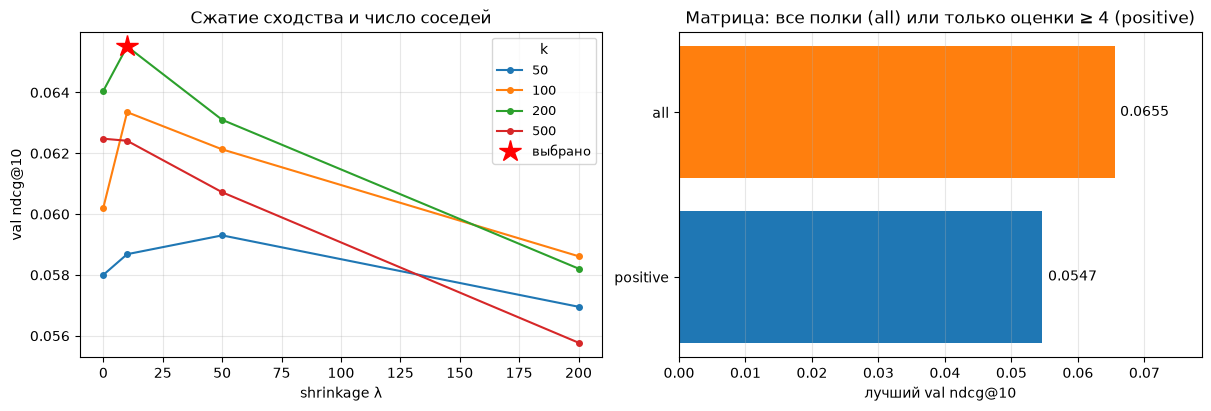

In [12]:
knn_grid, best_knn = ex.tune_itemknn(val, FORCE)
print("лучшее:", best_knn)
report.fig_itemknn(knn_grid, best_knn);

### 4.2 iALS

iALS для неявной обратной связи (Hu, Koren, Volinsky, 2008):

$$L=\sum_{u,i}c_{ui}(p_{ui}-x_u^\top y_i)^2+\lambda(\|X\|_F^2+\|Y\|_F^2).$$

Для известных полок $p_{ui}=1$, $c_{ui}=1+\alpha$; для ненаблюдаемых пар $p_{ui}=0$, $c_{ui}=1$. Скоринг: $x_u^\top y_i$.
При фиксированном $Y$ обновляем пользователя из $A_ux_u=b_u$:

$$A_u=Y^\top Y+\sum_{i\in I_u}(c_{ui}-1)y_iy_i^\top+\lambda I,\qquad
b_u=\sum_{i\in I_u}c_{ui}p_{ui}y_i.$$

Обновление произведений симметрично. Выполняем 15 итераций ALS, по 4 шага сопряжённых градиентов на обновление, с предыдущими факторами как начальным приближением. Вычисления - PyTorch на GPU или CPU; проверка против точного решения - `tests/test_ials.py`.

Сетка: $d\in\{32,64,128,256\}$, $\lambda\in\{0.1,1,10,100,300,1000\}$, $\alpha\in\{1,2,5,10,20,50\}$. Выбор - по val NDCG@10; значения за пределами сетки не проверялись.


лучшее: {'factors': 256, 'reg': 300.0, 'alpha': 50}


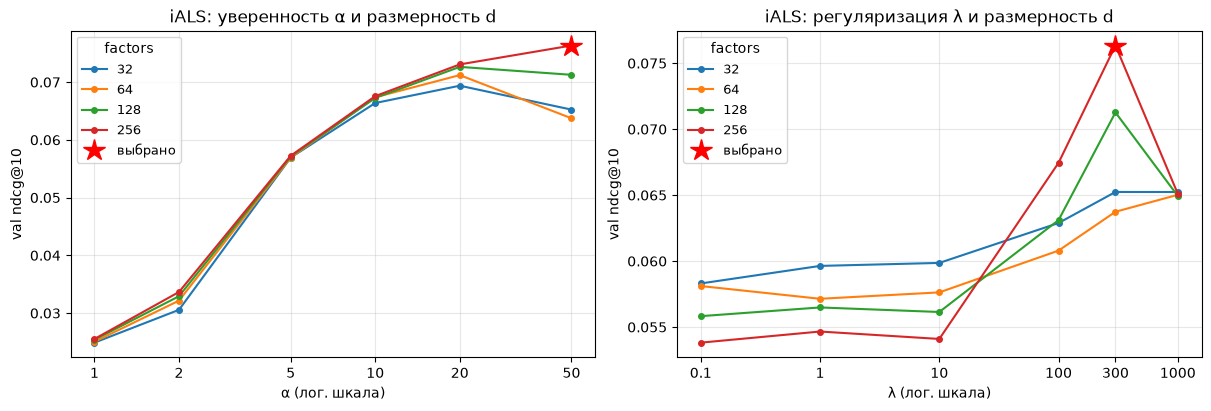

In [13]:
ials_grid, best_ials = ex.tune_ials(val, FORCE)
print("лучшее:", best_ials)
report.fig_ials(ials_grid, best_ials);

### 4.3 EASE

EASE (Steck, 2019) - линейная item-item модель:

$$\min_B\|X-XB\|_F^2+\lambda\|B\|_F^2,\quad \operatorname{diag}B=0;\qquad
P=(X^\top X+\lambda I)^{-1},\quad B_{ij}=-P_{ij}/P_{jj}\ (i\ne j),\quad B_{jj}=0.$$

$X$ - бинарная матрица взаимодействий; скоринг пользователя - $X_uB$. Решение вычисляем через разложение Холецкого в float64 на CPU; матрицу весов используем в float32 для скоринга. Проверка - `tests/test_ease.py`.

Сетка: $\lambda\in\{50,100,200,500,1000,2000,5000\}$; вход - все полки или только известные к cutoff оценки ≥ 4.


лучшее: {'reg': 500, 'source': 'all'}


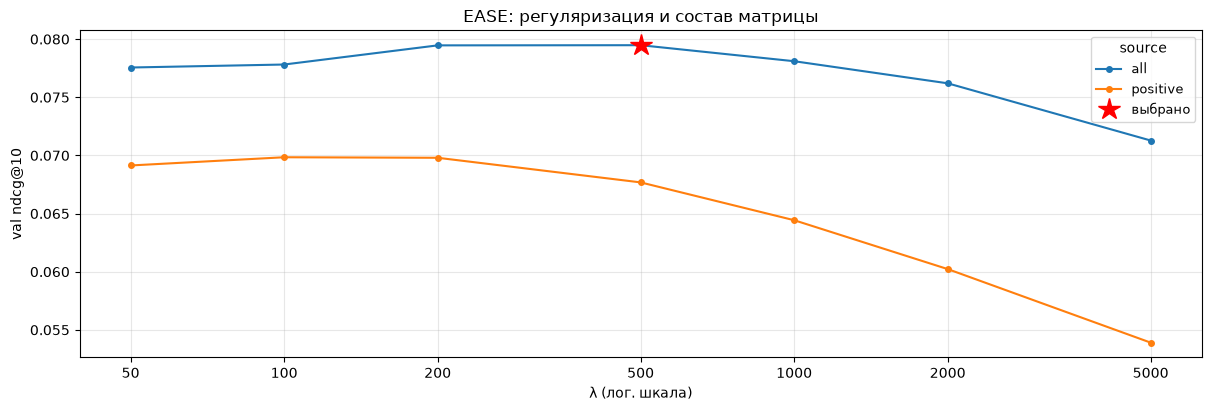

In [14]:
ease_grid, best_ease = ex.tune_ease(val, FORCE)
print("лучшее:", best_ease)
report.fig_ease(ease_grid, best_ease);

### 4.4 Factorization Machine с метапризнаками

FM второго порядка (Rendle, 2010) с BPR (Rendle et al., 2009):

$$s(x)=\sum_a w_ax_a+\sum_{a<b}\langle v_a,v_b\rangle x_ax_b,\qquad x=[x_u;x_i].$$

Положительный пример $i$ - известная полка; $j$ - книга без взаимодействия с пользователем, равномерно выбранная из допустимого каталога. Для $e_z=\sum_{a\in z}v_ax_a$ и $t_z=\sum_{a\in z}w_ax_a+\tfrac12(\|e_z\|^2-\sum_{a\in z}\|v_a\|^2x_a^2)$:

$$L=\mathbb E_{(u,i,j)}\left[\operatorname{softplus}(-(s(u,i)-s(u,j)))
+\lambda(\|e_u\|^2+\|e_i\|^2+\|e_j\|^2)+\lambda_b(t_i^2+t_j^2)\right],\quad \lambda_b=10^{-6}.$$

Обучение - Adam, батч 8192. Для ранжирования используем $s(u,i)=t_i+\langle e_u,e_i\rangle$, опуская постоянную пользователя. Формула скоринга и градиент проверены в `tests/test_fm.py`.

| Сторона | Признаки | Назначение |
|---|---|---|
| Книга | ID | Коллаборативный сигнал |
| Книга | Первый автор (до 3000), год, страницы, формат, язык, издатель | Авторство и характеристики произведения/изданий |
| Книга | TF-IDF описания (до 3000 слов), корзина популярности | Текстовое сходство и популярность по истории |
| Пользователь | ID, активность, средняя оценка, доля полок без оценки и прочтения | Характеристики истории |
| Пользователь | Профиль авторов: наличие авторов в истории | Связь предпочтений с авторством книги |

Каждая непустая группа признаков нормируется к сумме 1. Словари строятся на доступном каталоге, пользовательские признаки и популярность - на истории до cutoff; границы числовых корзин фиксированы заранее.

Сетка: $d=64$, lr ∈ {0.001, 0.003}, $\lambda$ ∈ {1e-5, 1e-4, 1e-3}; эпохи {1, 2, 5, 10, 20, 30, 40, 50, 60}. Затем при выбранных lr и $\lambda$ сравниваем ID, ID + книга, ID + книга + пользователь, выбирая эпоху на validation для каждого набора.


лучшее: {'feature_set': 'ids+item+user', 'factors': 64, 'lr': 0.001, 'reg': 0.001, 'epochs': 30}


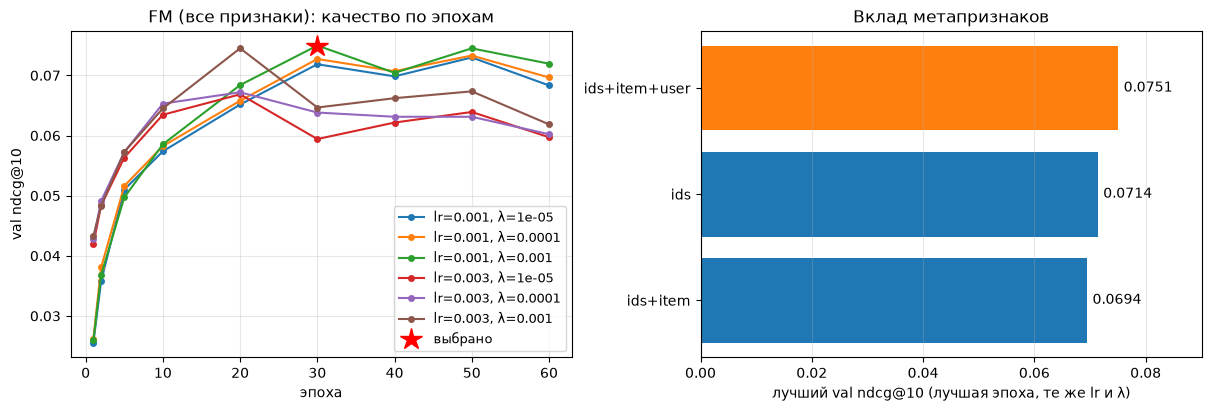

In [15]:
fm_grid, fm_abl, best_fm = ex.tune_fm(val, FORCE)
print("лучшее:", best_fm)
report.fig_fm(fm_grid, fm_abl, best_fm);

### 4.5 iALS с собственным целевым сигналом

Используем решатель и функцию потерь модели 2, изменяя цель на затухающий интерес к cutoff. Для наблюдаемых пар:

$$d_{ui}=2^{-\Delta t_{ui}/h},\qquad
s_{ui}=\begin{cases}\sigma((r_{ui}-m_u+b)/\tau),&\text{есть оценка и }\tau\ne\mathrm{None},\\1,&\text{иначе},\end{cases}\qquad
m_u=\frac{\sum_{i:\,r_{ui}\text{ известна}}r_{ui}+\kappa\mu}{n_u+\kappa}.$$

$\mu$ - средняя известная оценка по истории, $n_u$ - число известных оценок пользователя; $\kappa=5$, $b=0.5$. $\Delta t$ - дни после последнего известного события пары (полка, оценка, прочтение). При $h=\mathrm{None}$ принимаем $d_{ui}=1$.

$$p_{ui}=d_{ui}s_{ui},\qquad c_{ui}=1+\alpha w_{ui}+\alpha_{rev}\mathbf1[\text{рецензия}],\qquad
w_{ui}=\begin{cases}w_{shelf},&\text{нет оценки и прочтения},\\1,&\text{иначе}.\end{cases}$$

Если $\alpha_{neg}\ne\mathrm{None}$, для известных оценок $r_{ui}\le2$ переопределяем $p_{ui}=0$, $c_{ui}=1+\alpha_{neg}$. Ненаблюдаемые пары: $p=0$, $c=1$.

Компоненты проверяют давность интереса, оценку относительно среднего пользователя, низкие оценки и уверенность по типу взаимодействия. Затухание меняет именно цель $p$. Контрольная абляция переносит тот же множитель в уверенность: $p=s$, $c=1+\alpha w d+\alpha_{rev}\mathbf1[\text{рецензия}]$, с той же обработкой низких оценок.

$d$, $\lambda$, $\alpha$ и параметры решателя фиксированы на лучшем iALS; подбираются компоненты цели и уверенности. При отключении всех компонент получаем модель 2.

Сетка: $h\in\{180,365,730,1095,1825\}$ дней, $\tau\in\{\mathrm{None},0.25,0.75\}$, $\alpha_{neg}\in\{\mathrm{None},10,40\}$, $w_{shelf}\in\{0.3,1\}$, $\alpha_{rev}\in\{0,5\}$.


In [16]:
sig_grid, best_sig = ex.tune_signal(val, best_ials, FORCE)
print("лучшее:", best_sig)
sig_grid.sort(config.PRIMARY_METRIC, descending=True).head(5).with_columns(pl.selectors.float().round(4))

лучшее: {'tau': None, 'alpha_neg': None, 'w_shelf': 0.3, 'half_life': 730, 'alpha_rev': 5}


tau,alpha_neg,w_shelf,half_life,alpha_rev,ndcg@10,recall@10,precision@10,hit@10,coverage@10,pop_rank_mean,users,fit_s
f64,i64,f64,i64,i64,f64,f64,f64,f64,f64,f64,i64,f64
null,null,0.3,730,5,0.1169,0.1771,0.0267,0.245,0.0659,0.0251,2555,3.8
null,null,0.3,730,0,0.1165,0.1767,0.0267,0.2446,0.0649,0.0246,2555,3.8
null,40,0.3,730,5,0.116,0.1792,0.0273,0.2458,0.0666,0.0247,2555,3.7
null,10,0.3,730,0,0.1156,0.178,0.0272,0.2466,0.0645,0.0239,2555,3.7
null,10,0.3,730,5,0.1155,0.1774,0.027,0.245,0.065,0.0243,2555,3.7


Цель $p$ при выбранных параметрах и вклад каждой компоненты на validation (выключаем по одной, refit, paired bootstrap по пользователям):

вариант,ndcg@10,delta,lo,hi
str,f64,f64,f64,f64
"""все компоненты выкл. (= модель 2)""",0.0763,-0.0406,-0.0489,-0.0326
"""без w_shelf""",0.1096,-0.0073,-0.0125,-0.0022
"""без half_life""",0.0809,-0.036,-0.044,-0.0289
"""без alpha_rev""",0.1165,-0.0004,-0.0013,0.0003
"""затухание в c, а не в p""",0.087,-0.03,-0.0368,-0.0237


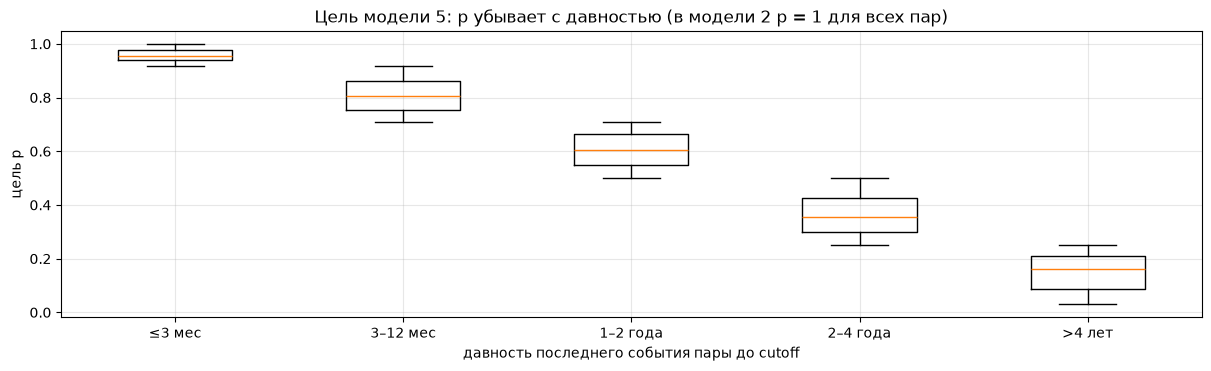

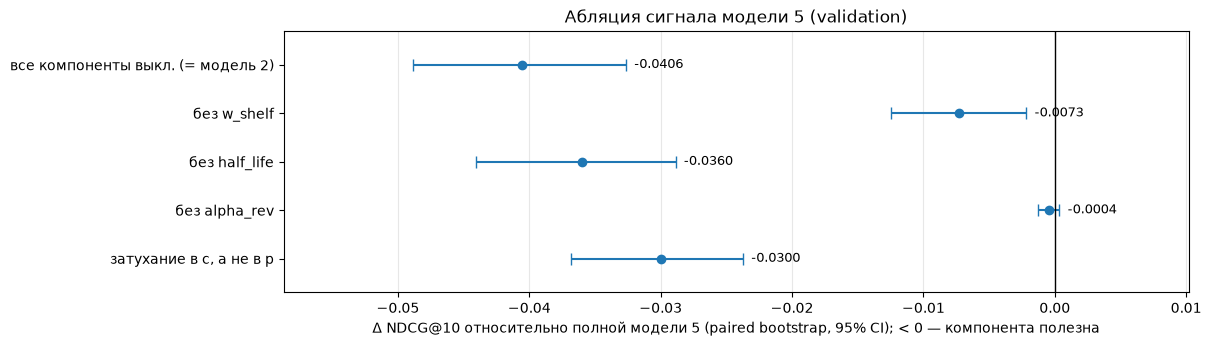

In [17]:
from models.ials_custom import CustomTargetIALS
diag = CustomTargetIALS(iters=1, **best_ials, **best_sig)
diag.signal(val.history)
report.fig_p_by_age(diag.diagnostics)
abl_val = ex.signal_ablation(val, best_ials, best_sig, force=FORCE)
report.fig_signal(abl_val, "validation");
abl_val.drop("params").with_columns(pl.selectors.float().round(4))

## 5. Финальное сравнение на test

Лучшие настройки каждой модели фиксированы на validation. Refit на истории до 2017-06-01 (train + val), один прогон на июнь-октябрь 2017.

In [18]:
best = {"pop_recent": best_pop, "knn": best_knn, "ials": best_ials, "ease": best_ease, "fm": best_fm, "custom": best_sig}
ex.save_best(best)
table, per_user = ex.run_test(test, best, FORCE)
cols = ["model", "ndcg@10", "ndcg_lo", "ndcg_hi", "recall@10", "hit@10", "precision@10", "coverage@10", "pop_rank_mean", "fit_s", "params"]
table.select(cols).sort("ndcg@10", descending=True).with_columns(pl.selectors.float().round(4))

model,ndcg@10,ndcg_lo,ndcg_hi,recall@10,hit@10,precision@10,coverage@10,pop_rank_mean,fit_s,params
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""iALS + custom target""",0.1187,0.1105,0.1273,0.1819,0.2562,0.0288,0.0655,0.023,5.1,"""{""factors"": 256, ""reg"": 300.0, ""alpha"": 50, ""tau"": null, ""alpha_neg"": null, ""w_s…"
"""EASE""",0.0844,0.0776,0.0917,0.1344,0.1969,0.0224,0.1395,0.02,7.5,"""{""reg"": 500, ""source"": ""all""}"""
"""FM""",0.0795,0.0726,0.0864,0.1326,0.1933,0.0216,0.1301,0.0267,46.7,"""{""feature_set"": ""ids+item+user"", ""factors"": 64, ""lr"": 0.001, ""reg"": 0.001, ""epoc…"
"""iALS""",0.0752,0.0687,0.0823,0.123,0.1831,0.0206,0.1793,0.031,4.9,"""{""factors"": 256, ""reg"": 300.0, ""alpha"": 50}"""
"""ItemKNN""",0.0686,0.062,0.0753,0.1091,0.1619,0.0188,0.1343,0.0261,0.9,"""{""k"": 200, ""shrinkage"": 10, ""source"": ""all""}"""
"""Recent popularity""",0.0685,0.0606,0.0764,0.0979,0.1276,0.0132,0.0027,0.0519,0.1,"""{""window_days"": 30}"""
"""Popularity""",0.0349,0.0302,0.0398,0.0582,0.0795,0.0094,0.005,0.0007,0.1,"""{}"""
"""Random""",0.0007,0.0002,0.0015,0.0011,0.0022,0.0002,0.869,0.5055,0.1,"""{}"""


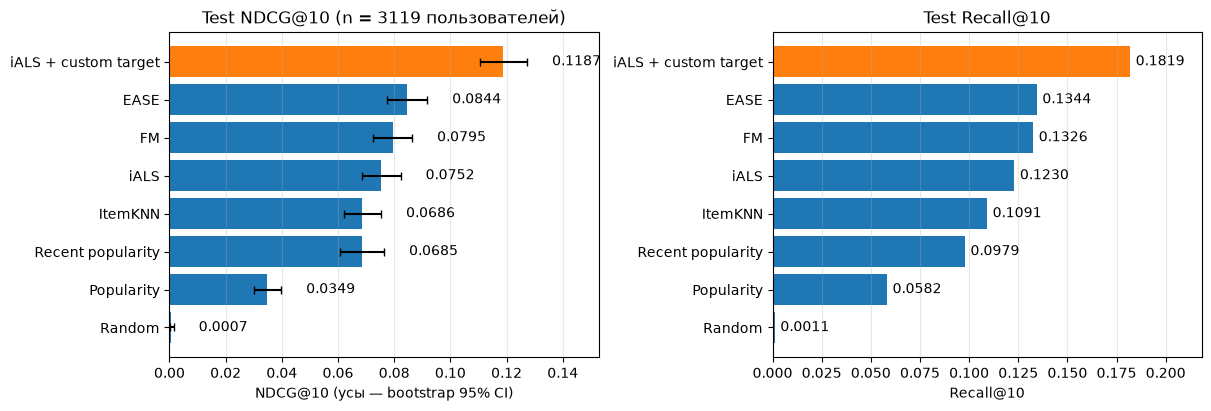

In [19]:
leader = table.sort("ndcg@10", descending=True)["model"][0]
report.fig_test_rank(table, highlight=leader);

Попарные разницы NDCG@10 с лучшей моделью (paired bootstrap по одним и тем же пользователям, 95% CI):

In [20]:
report.pairwise_vs(per_user, leader).with_columns(pl.selectors.float().round(4))

model,Δ NDCG@10 vs iALS + custom target,lo,hi
str,f64,f64,f64
"""Random""",-0.118,-0.1267,-0.1097
"""Popularity""",-0.0838,-0.0926,-0.0749
"""Recent popularity""",-0.0502,-0.0594,-0.0416
"""ItemKNN""",-0.0501,-0.0582,-0.0422
"""iALS""",-0.0435,-0.0509,-0.0363
"""EASE""",-0.0343,-0.0418,-0.0271
"""FM""",-0.0392,-0.0466,-0.0319


### Влияние собственного сигнала (модель 5 против модели 2) и вклад его компонент на test

вариант,ndcg@10,delta,lo,hi
str,f64,f64,f64,f64
"""все компоненты выкл. (= модель 2)""",0.0752,-0.0435,-0.0509,-0.0363
"""без w_shelf""",0.1168,-0.0019,-0.0069,0.0026
"""без half_life""",0.0822,-0.0364,-0.0433,-0.0297
"""без alpha_rev""",0.118,-0.0007,-0.0014,0.0001
"""затухание в c, а не в p""",0.0949,-0.0237,-0.0298,-0.0176


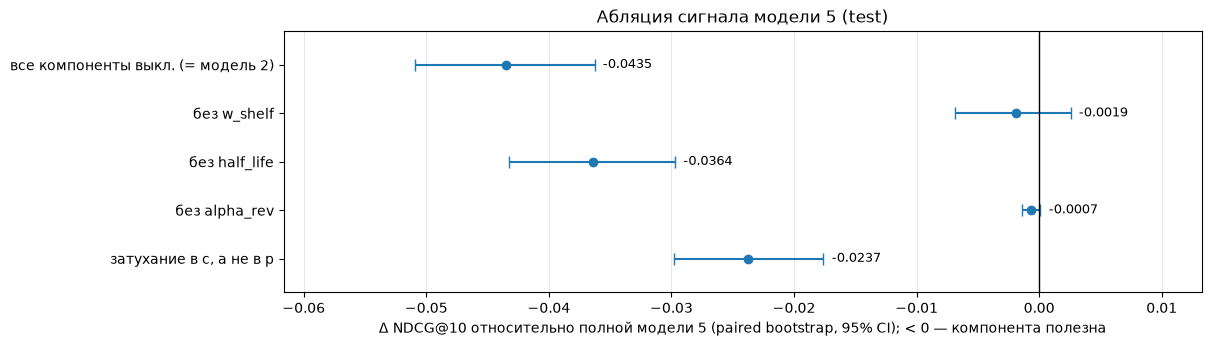

In [21]:
abl_test = ex.signal_ablation(test, best_ials, best_sig, per_user[ex.NAMES["custom"]]["ndcg"], FORCE)
report.fig_signal(abl_test, "test");
abl_test.drop("params").with_columns(pl.selectors.float().round(4))

### Кому помогают модели: качество по длине истории

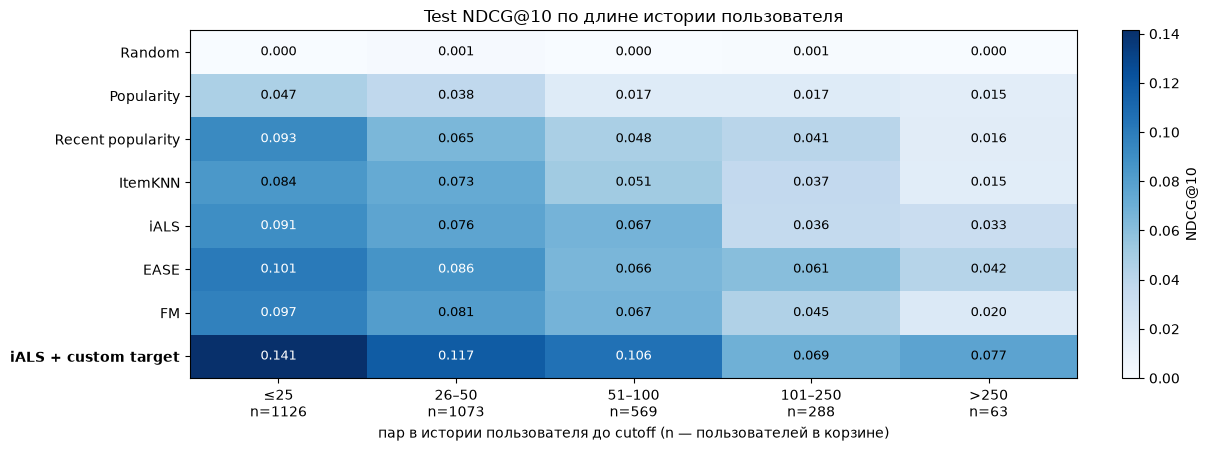

In [22]:
report.fig_by_activity(per_user, test, highlight=leader);

### Популярность рекомендаций

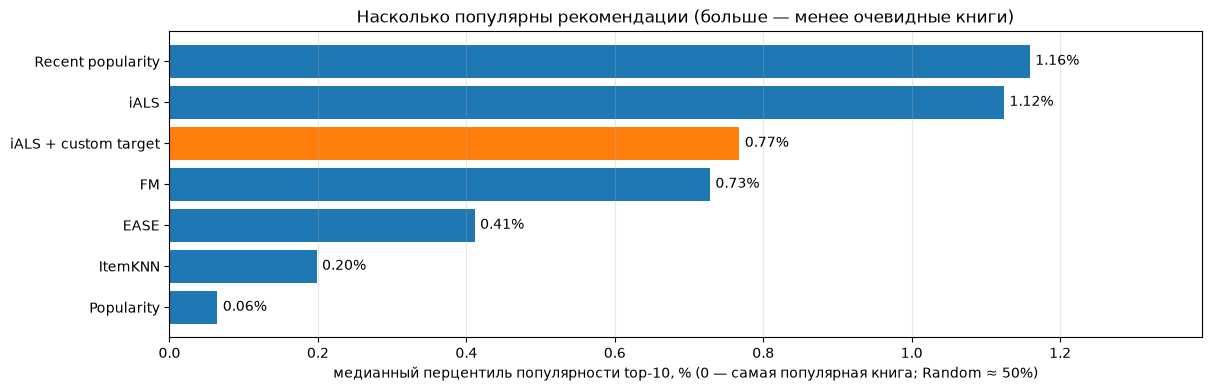

In [23]:
recs = ex.tuning.load_recs()
report.fig_popularity_of_recs(recs, test, highlight=leader);

Рекомендации моделей смещены к популярным произведениям: меньший перцентиль означает большую популярность по истории до cutoff. Recent popularity тоже использует популярность, но только за последние 30 дней, поэтому её рекомендации могут отличаться от лидеров за всю историю. Этот график описывает популярность рекомендаций; разнообразие внутри списков он не измеряет.


### Пример: история одного пользователя и top-10 (● - книга, которую он потом добавил и оценил ≥ 4)

In [24]:
hist, top10, uid = report.example_user(recs, test, items, [leader, ex.NAMES["custom"], ex.NAMES["fm"]])
print("пользователь", uid, "- последние полки до 2017-06-01:")
display(hist)
top10

пользователь 16499 - последние полки до 2017-06-01:


полка,оценка,книга
date,i8,str
2017-04-02,4,"""Blackacre : Poems - Monica Youn"""
2017-03-25,null,"""The Dogs I Have Kissed - Trista Mateer"""
2017-03-06,null,"""Black Butterfly - Robert M. Drake"""
2017-03-03,null,"""I Want to Be Once - M.L. Liebler"""
2017-03-03,5,"""Poisoned Apples: Poems for You, My Pre - Christine Hepperma"""
2017-02-25,null,"""Quarter Life Poetry: Poems for the You - Samantha Jayne"""


#,iALS + custom target,FM
i64,str,str
1,"""Night Sky with Exit Wounds - Ocean Vuong""","""Howl and other poems - Allen Ginsberg"""
2,"""Howl and other poems - Allen Ginsberg""","""● Complete Poems, 1904-1962 - E.E. Cummings"""
3,"""The Collected Poems - Sylvia Plath""","""The Road Not Taken: A Selection of Rob - Robert Frost"""
4,"""Grief is the Thing with Feathers - Max Porter""","""Sonetti - William Shakespear"""
5,"""Brown Girl Dreaming - Jacqueline Woodson""","""The Leaves of Grass - Walt Whitman"""
6,"""Salt - Nayyirah Waheed""","""Pop Sonnets: Shakespearean Spins on Yo - Erik Didriksen"""
7,"""No Matter the Wreckage - Sarah Kay""","""The Hell of Dante of Dante Aligheri - Dante Alighieri"""
8,"""The Colossus and Other Poems - Sylvia Plath""","""The Raven and Other Poems - Edgar Allan Poe"""
9,"""Birthday Letters - Ted Hughes""","""Paradise lost - John Milton"""


## 6. Выводы

**Итог на test** (июнь-октябрь 2017, 3 119 пользователей, refit на train + val, NDCG@10 [95% CI]):

| место | модель | NDCG@10 | Recall@10 | выбранные параметры |
|---|---|---|---|---|
| 1 | iALS + custom target | **0.1187** [0.1105; 0.1273] | **0.1819** | $d=256,\ \lambda=300,\ \alpha=50$; $h=730$ дн., $w_{shelf}=0.3$, $\alpha_{rev}=5$, $\tau$ = None, без отдельной обработки низких оценок |
| 2 | EASE | 0.0844 [0.0776; 0.0917] | 0.1344 | $\lambda=500$, все полки |
| 3 | FM | 0.0795 [0.0726; 0.0864] | 0.1326 | ID + книга + пользователь, $d=64$, lr = 0.001, $\lambda=10^{-3}$, 30 эпох |
| 4 | iALS | 0.0752 [0.0687; 0.0823] | 0.1230 | $d=256,\ \lambda=300,\ \alpha=50$ |
| 5 | ItemKNN | 0.0686 [0.0620; 0.0753] | 0.1091 | $k=200$, $\lambda=10$, все полки |
| - | Recent popularity | 0.0685 [0.0606; 0.0764] | 0.0979 | окно 30 дней |
| - | Popularity | 0.0349 | 0.0582 | - |
| - | Random | 0.0007 | 0.0011 | - |

**1. Время - важный фактор.** Recent popularity с окном 30 дней даёт NDCG@10 = 0.0685 против 0.0349 у популярности за всю историю и почти совпадает с ItemKNN (0.0686). В этом эксперименте учёт времени полезен как для неперсонального бейзлайна, так и для цели iALS.

**2. Модель 5 показала лучшее качество.** При тех же параметрах факторизации и решателе её NDCG@10 выше базового iALS на 0.0435 (+58%; paired bootstrap 95% CI [0.0363; 0.0509]), EASE - на 0.0343 [0.0271; 0.0418]. Без затухания качество снижается на 0.0364; перенос затухания из цели в уверенность снижает его на 0.0237 [0.0176; 0.0298]. Это подтверждает полезность изменения цели в выбранном протоколе.

**3. Результат сохраняется на test.** Модель 5 и EASE лидируют и на validation, и на test; FM и iALS меняются местами.

**4. Не все компоненты сигнала полезны.** Возможное объяснение - преобладание высоких оценок и сохранение информации о круге чтения даже в низко оценённых книгах; отдельно это объяснение не проверялось. На test эффекты веса полки и бонуса рецензии неубедительны: 95% интервалы разниц при их отключении включают ноль.

**5. Метапризнаки пользователя помогли FM.** При общих выбранных lr и $\lambda$ лучший val NDCG@10 составляет 0.0714 для ID, 0.0694 для ID + книга и 0.0751 для ID + книга + пользователь. Признаки книги сами по себе улучшения не дали; добавление пользовательских признаков, включая профиль авторов, повысило качество. Отдельный вклад профиля авторов этой абляцией не выделен. На test полный FM достигает 0.0795 против 0.0844 у EASE.

**6. Лучшее качество сопровождается меньшим покрытием каталога.** Coverage@10 модели 5 - 6.5% против 17.9% у iALS и 13.9% у EASE. Рекомендации модели 5 охватывают меньше произведений по всей оцениваемой аудитории. Это ограничение покрытия; разнообразие внутри отдельных списков не измерялось.

**Ограничения эксперимента:**

- Один жанр и одно test-окно (июнь-октябрь 2017); переносимость результатов на другие жанры и периоды не проверялась.
- Оценка только на пользователях и произведениях, оставшихся после 15-core по train, и пользователях с релевантными книгами в окне. Холодный старт и пользователи без таких книг не оценивались.
- `date_updated` используется как приближение времени оценки; полной истории изменений нет. Метаданные книг также представлены снимком без истории редактирования.
- Один seed обучения. Пользовательский bootstrap оценивает неопределённость метрик при фиксированных обученных моделях, но не вариативность между повторными обучениями.
- Поиск ограничен заданными сетками; параметры факторизации модели 5 взяты у базового iALS и отдельно под новую цель не подбирались.
